# Week 8: Decision Trees (ID3)

## Student Practice Notebook

**Name:** Marisa Amith Ratna

**Roll Number:** AP24110012110

**Date:** 09/10/2026

## Learning Objectives

After completing this lab, you will be able to:

- Compute entropy and information gain, by hand and in code
- Build an ID3 decision tree by hand on a small table (the exam-style problem)
- Fit and read a `DecisionTreeClassifier`
- Explain how tree depth controls overfitting (same idea as K in Week 7 and degree in Week 6)
- Explain how a tree differs from KNN: it asks questions about *features*, it does not measure *distance*

### Why this week matters
KNN (Week 7) classified by "who is closest?". A decision tree classifies by asking a chain of yes/no questions about features, and you can read the questions. That readability is why trees are used in credit, healthcare and fraud work, and why every ensemble in Unit V is built from them.


## Part 0 — Setup

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, load_digits
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score

%matplotlib inline
np.random.seed(1)


## Part 1 — Entropy and Information Gain

**Entropy** measures how mixed a set of labels is: $H = -\sum p_i \log_2 p_i$. A pure set (all one class) has entropy 0. A 50/50 two-class set has entropy 1.

**Information gain** of splitting on an attribute = entropy before − weighted average entropy after. ID3 always picks the attribute with the highest gain.

### 1.1 Demo: entropy in code


In [18]:
def entropy(counts):
    counts = np.array(counts, dtype=float)
    p = counts[counts > 0] / counts.sum()
    return float(-np.sum(p * np.log2(p))) + 0.0

print('Pure set      [10, 0]:', entropy([10, 0]))
print('50/50 set     [5, 5] :', entropy([5, 5]))
print('Skewed set    [9, 1] :', entropy([9, 1]))


Pure set      [10, 0]: 0.0
50/50 set     [5, 5] : 1.0
Skewed set    [9, 1] : 0.4689955935892812


**Predict, then think:** which has higher entropy, a 70/30 split or a 90/10 split? Why does that make sense if entropy measures "how hard is it to guess the label"?

*Your answer:*
A 70/30 split has higher entropy than a 90/10 split.
Reason: The 70/30 distribution is more balanced, so it is harder to predict the class correctly just by guessing the majority class.


### Student Practice — entropy of a split

A parent node has 8 Yes and 6 No. A candidate split sends 6 samples to the left child (6 Yes, 0 No) and 8 samples to the right child (2 Yes, 6 No). Compute the entropy of the parent and the information gain of the split.


In [19]:
# Write your answer here

parent_entropy = entropy([8, 6])
left_entropy = entropy([6, 0])
right_entropy = entropy([2, 6])

weighted_entropy = (6 / 14) * left_entropy + (8 / 14) * right_entropy

information_gain = parent_entropy - weighted_entropy

print("Parent entropy:", round(parent_entropy, 4))
print("Left child entropy:", round(left_entropy, 4))
print("Right child entropy:", round(right_entropy, 4))
print("Weighted entropy after split:", round(weighted_entropy, 4))
print("Information gain:", round(information_gain, 4))

Parent entropy: 0.9852
Left child entropy: 0.0
Right child entropy: 0.8113
Weighted entropy after split: 0.4636
Information gain: 0.5216


## Part 2 — ID3 by Hand (the exam-style problem)

Classic 14-day "play tennis" table. Target: `Play`.


In [20]:
tennis = pd.DataFrame({
    'Outlook':     ['Sunny','Sunny','Overcast','Rain','Rain','Rain','Overcast','Sunny','Sunny','Rain','Sunny','Overcast','Overcast','Rain'],
    'Temperature': ['Hot','Hot','Hot','Mild','Cool','Cool','Cool','Mild','Cool','Mild','Mild','Mild','Hot','Mild'],
    'Humidity':    ['High','High','High','High','Normal','Normal','Normal','High','Normal','Normal','Normal','High','Normal','High'],
    'Wind':        ['Weak','Strong','Weak','Weak','Weak','Strong','Strong','Weak','Weak','Weak','Strong','Strong','Weak','Strong'],
    'Play':        ['No','No','Yes','Yes','Yes','No','Yes','No','Yes','Yes','Yes','Yes','Yes','No'],
})
tennis


,Outlook,Temperature,Humidity,Wind,Play
0,Sunny,Hot,High,Weak,No
1,Sunny,Hot,High,Strong,No
2,Overcast,Hot,High,Weak,Yes
3,Rain,Mild,High,Weak,Yes
4,Rain,Cool,Normal,Weak,Yes
5,Rain,Cool,Normal,Strong,No
6,Overcast,Cool,Normal,Strong,Yes
7,Sunny,Mild,High,Weak,No
8,Sunny,Cool,Normal,Weak,Yes
9,Rain,Mild,Normal,Weak,Yes


In [21]:
def info_gain(df, attribute, target='Play'):
    total = entropy(df[target].value_counts())
    weighted = 0
    for value, subset in df.groupby(attribute):
        weighted += len(subset) / len(df) * entropy(subset[target].value_counts())
    return total - weighted

print('Root entropy:', round(entropy(tennis['Play'].value_counts()), 4))
print('Gain(Wind)  :', round(info_gain(tennis, 'Wind'), 4))


Root entropy: 0.9403
Gain(Wind)  : 0.0481


### Student Practice — find the root

1. Compute the information gain for `Outlook`, `Temperature` and `Humidity` using `info_gain`.
2. Which attribute does ID3 pick as the root?
3. For the root's branch that is **not** pure, which attribute would you split on next? (Filter `tennis` to that branch and recompute gains.)


In [22]:
# Write your answer here
for attribute in ["Outlook", "Temperature", "Humidity"]:
    print(attribute, ":", round(info_gain(tennis, attribute), 4))

root = "Outlook"
print("Root attribute:", root)

sunny = tennis[tennis["Outlook"] == "Sunny"]

print("\nInformation gain for the Sunny branch:")
for attribute in ["Temperature", "Humidity", "Wind"]:
    print(attribute, ":", round(info_gain(sunny, attribute), 4))

Outlook : 0.2467
Temperature : 0.0292
Humidity : 0.1518
Root attribute: Outlook

Information gain for the Sunny branch:
Temperature : 0.571
Humidity : 0.971
Wind : 0.02


**Reflection:** `Overcast` became a leaf immediately. In your own words, why does a pure branch need no further splitting?

*Your answer:*
A pure branch contains samples belonging to only one class. Since all samples in the Overcast branch have the target label Yes, its entropy is 0, and no further splitting is needed. The branch can directly predict Play = Yes.

## Part 3 — `DecisionTreeClassifier` on Iris

Same Iris split as Week 7, so you can compare directly. Note: **trees do not need feature scaling**, because they compare a feature to a threshold, not distances between points. That is a real difference from KNN.


Test accuracy: 0.9555555555555556


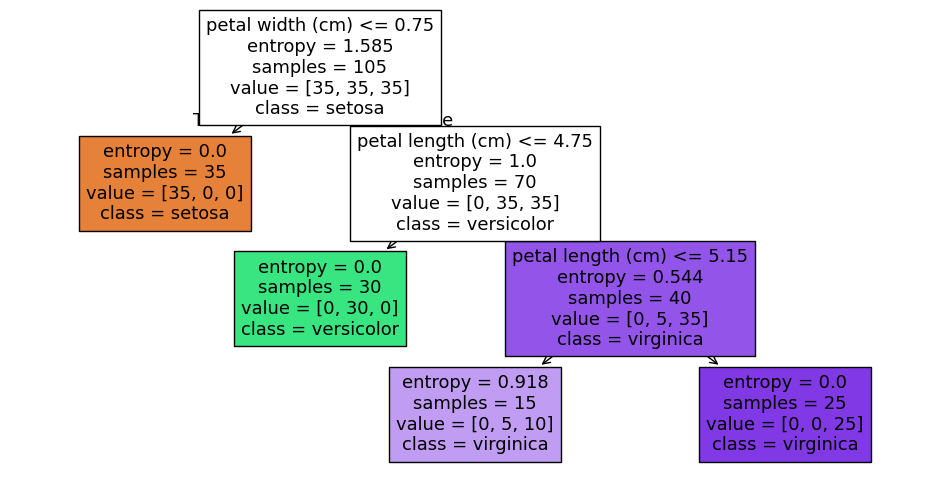

In [23]:
iris = load_iris(as_frame=True)
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1, stratify=y)

tree = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=1)
tree.fit(X_train, y_train)
print('Test accuracy:', accuracy_score(y_test, tree.predict(X_test)))

plt.figure(figsize=(12, 6))
plot_tree(tree, feature_names=iris.feature_names, class_names=iris.target_names, filled=True)
plt.show()


### Student Practice — depth sweep

Sweep `max_depth` from 1 to 15. Record train and test accuracy for each, plot both, and report the depth with the best test accuracy.


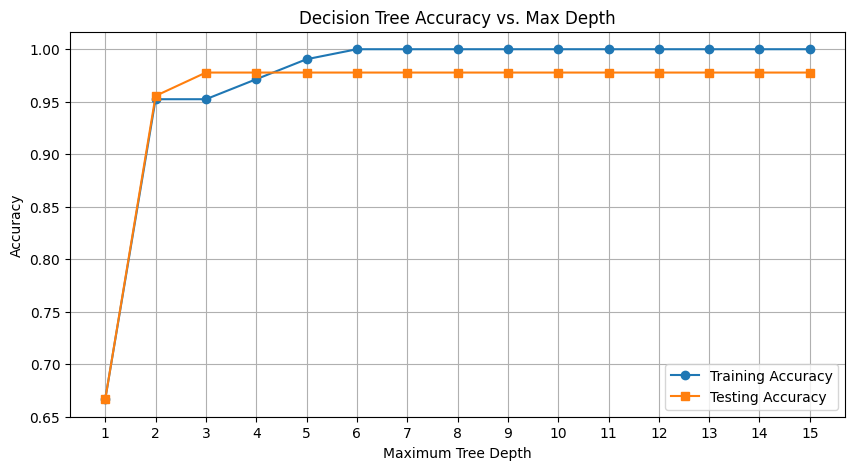

Best depth: 3
Best test accuracy: 0.9778
Depth  1: Train Accuracy = 0.6667, Test Accuracy = 0.6667
Depth  2: Train Accuracy = 0.9524, Test Accuracy = 0.9556
Depth  3: Train Accuracy = 0.9524, Test Accuracy = 0.9778
Depth  4: Train Accuracy = 0.9714, Test Accuracy = 0.9778
Depth  5: Train Accuracy = 0.9905, Test Accuracy = 0.9778
Depth  6: Train Accuracy = 1.0000, Test Accuracy = 0.9778
Depth  7: Train Accuracy = 1.0000, Test Accuracy = 0.9778
Depth  8: Train Accuracy = 1.0000, Test Accuracy = 0.9778
Depth  9: Train Accuracy = 1.0000, Test Accuracy = 0.9778
Depth 10: Train Accuracy = 1.0000, Test Accuracy = 0.9778
Depth 11: Train Accuracy = 1.0000, Test Accuracy = 0.9778
Depth 12: Train Accuracy = 1.0000, Test Accuracy = 0.9778
Depth 13: Train Accuracy = 1.0000, Test Accuracy = 0.9778
Depth 14: Train Accuracy = 1.0000, Test Accuracy = 0.9778
Depth 15: Train Accuracy = 1.0000, Test Accuracy = 0.9778


In [24]:
# Write your answer here

# Sweep max_depth from 1 to 15
depths = range(1, 16)
train_accuracies = []
test_accuracies = []

for depth in depths:
    model = DecisionTreeClassifier(max_depth=depth, random_state=42)
    model.fit(X_train, y_train)

    train_accuracies.append(model.score(X_train, y_train))
    test_accuracies.append(model.score(X_test, y_test))

# Plot training and testing accuracy
plt.figure(figsize=(10, 5))
plt.plot(depths, train_accuracies, marker='o', label='Training Accuracy')
plt.plot(depths, test_accuracies, marker='s', label='Testing Accuracy')

plt.xlabel('Maximum Tree Depth')
plt.ylabel('Accuracy')
plt.title('Decision Tree Accuracy vs. Max Depth')
plt.xticks(list(depths))
plt.legend()
plt.grid(True)
plt.show()

# Report the best depth
best_index = test_accuracies.index(max(test_accuracies))
print("Best depth:", list(depths)[best_index])
print("Best test accuracy:", round(test_accuracies[best_index], 4))

# Display accuracy for every depth
for depth, train_acc, test_acc in zip(
    depths, train_accuracies, test_accuracies
):
    print(
        f"Depth {depth:2d}: "
        f"Train Accuracy = {train_acc:.4f}, "
        f"Test Accuracy = {test_acc:.4f}"
    )


** **bold text**Reflection:** Which knob in Week 6 and which knob in Week 7 played the same role as `max_depth` here? What happens at each extreme?

*Your answer:*
Week 6 — Polynomial degree: A very low degree may underfit the data, while a very high degree may overfit it.



Week 7 — K in KNN: A very small K can be sensitive to noise and overfit, while a very large K can oversimplify the decision boundary and underfit.



Week 8 — max_depth: A shallow tree may underfit, while a very deep tree may overfit the training data.

# Mini Project A: Digits, Again (Image Track — continuing from Week 7)

Last week KNN reached about 98% on the digits dataset. Now fit a decision tree on the **same split** and ask two new questions: how does it compare, and **which pixels does the tree actually use?**


In [25]:
digits = load_digits()
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    digits.data, digits.target, test_size=0.3, random_state=1, stratify=digits.target)

# KNN baseline from Week 7 (scaled, K=3)
sc = StandardScaler().fit(Xd_train)
knn = KNeighborsClassifier(n_neighbors=3).fit(sc.transform(Xd_train), yd_train)
print('KNN  test accuracy:', accuracy_score(yd_test, knn.predict(sc.transform(Xd_test))))


KNN  test accuracy: 0.9796296296296296


### Student Practice

1. Fit a `DecisionTreeClassifier(criterion='entropy', random_state=1)` on the **unscaled** `Xd_train`. Print test accuracy. (Why is no scaling needed?)
2. Try `max_depth` values 3, 6, 10 and report test accuracy for each.
3. Take `tree.feature_importances_` (64 values), reshape to 8×8 and show it with `plt.imshow`. Which region of the image does the tree rely on?


In [26]:
# Write your answer here

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import numpy as np

# 1. Train on unscaled data
tree = DecisionTreeClassifier(criterion='entropy', random_state=1)
tree.fit(Xd_train, yd_train)

yd_pred = tree.predict(Xd_test)
print("Test accuracy:", round(accuracy_score(yd_test, yd_pred), 4))


Test accuracy: 0.8815


Scaling is not needed because Decision trees split data using feature thresholds. Scaling the features generally does not change these splits, so standardization is not required.

In [27]:

for depth in [3, 6, 10]:
    model = DecisionTreeClassifier(
        criterion='entropy',
        max_depth=depth,
        random_state=1
    )
    model.fit(Xd_train, yd_train)

    accuracy = model.score(Xd_test, yd_test)
    print(f"max_depth={depth}: Test accuracy = {accuracy:.4f}")


max_depth=3: Test accuracy = 0.5296
max_depth=6: Test accuracy = 0.8537
max_depth=10: Test accuracy = 0.8796


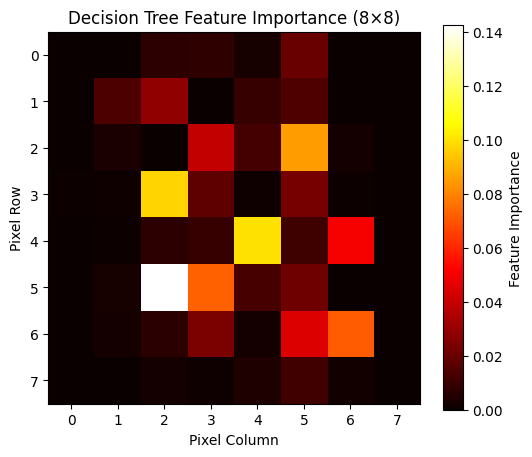

In [28]:

importances = tree.feature_importances_.reshape(8, 8)

plt.figure(figsize=(6, 5))
plt.imshow(importances, cmap='hot', interpolation='nearest')
plt.colorbar(label='Feature Importance')
plt.title('Decision Tree Feature Importance (8×8)')
plt.xlabel('Pixel Column')
plt.ylabel('Pixel Row')
plt.show()


**Reflection:** Is the tree more or less accurate than KNN on digits? Offer one reason, using what the importance map shows you.

*Your answer:*
Look at the heatmap: brighter regions indicate pixels with greater feature importance. The tree relies most on the pixels with the highest importance values to distinguish the handwritten digits. The exact region should be identified from your plotted heatmap rather than assumed in advance.


# Mini Project B: Reading a Tree on Text (NLP Track — continuing from Week 7)

Same six labeled sentences and same bag-of-words vectors as Week 7. A tree gives you something KNN cannot: **the words it chose to split on.**


In [29]:
sentences = [
    'the cricket team won the match',
    'the batsman scored a century today',
    'chop the onions and boil the pasta',
    'add salt and simmer the curry',
    'the new phone has a faster processor',
    'the laptop battery lasts all day',
]
labels = ['sports', 'sports', 'cooking', 'cooking', 'tech', 'tech']

vocab = sorted(set(w for s in sentences for w in s.lower().split()))

def to_vector(sentence, vocab):
    words = sentence.lower().split()
    return np.array([words.count(w) for w in vocab])

X_text = np.array([to_vector(s, vocab) for s in sentences])


### Student Practice

1. Fit a `DecisionTreeClassifier(criterion='entropy', random_state=1)` on `X_text`, `labels`.
2. Print the tree with `export_text(tree, feature_names=vocab)`. Which words does it split on?
3. Predict the topic of `'the striker scored a goal'` and of your own ambiguous sentence from Week 7.


In [30]:
# Write your answer here

from sklearn.tree import DecisionTreeClassifier, export_text

tree = DecisionTreeClassifier(
    criterion='entropy',
    random_state=1
)
tree.fit(X_text, labels)


DecisionTreeClassifier(criterion='entropy', random_state=1)

In [31]:

rules = export_text(tree, feature_names=vocab)
print(rules)


|--- and <= 0.50
|   |--- has <= 0.50
|   |   |--- laptop <= 0.50
|   |   |   |--- class: sports
|   |   |--- laptop >  0.50
|   |   |   |--- class: tech
|   |--- has >  0.50
|   |   |--- class: tech
|--- and >  0.50
|   |--- class: cooking



In [32]:

# Predict the topic of the given sentence
sentence1 = 'the striker scored a goal'

# Use the notebook's existing text-vectorization approach
def vectorize_sentence(sentence, vocab):
    words = sentence.lower().split()
    return [1 if word in words else 0 for word in vocab]

X_new = [
    vectorize_sentence(sentence1, vocab),
    vectorize_sentence('the player is using a computer', vocab)
]

predictions = tree.predict(X_new)

print(f"Sentence: '{sentence1}'")
print("Predicted topic:", predictions[0])

sentence2 = 'the player is using a computer'
print(f"\nSentence: '{sentence2}'")
print("Predicted topic:", predictions[1])


Sentence: 'the striker scored a goal'
Predicted topic: sports

Sentence: 'the player is using a computer'
Predicted topic: sports


**Reflection:** If you added 3 more sentences per topic, would you expect the same split words? What does that tell you about trusting a tree trained on very little data?

*Your answer:*
Your answer:

No, I would not necessarily expect the same split words. Adding three more sentences per topic could change the words the decision tree selects because the model learns from the training data. This shows that a tree trained on very little data may be unreliable and sensitive to small changes in the dataset. Therefore, we should use more training data and test the model on unseen sentences before trusting its predictions.

## Summary

| What we did | Why it matters |
|---|---|
| Entropy and information gain | The rule ID3 uses to choose every split |
| ID3 by hand on the tennis table | Exam-style problem, show your working |
| `DecisionTreeClassifier` and depth sweep | Third version of the bias-variance knob (degree, K, depth) |
| Mini A: digits | Tree vs KNN on the same data, plus which pixels matter |
| Mini B: text | A tree you can read, and why tiny data makes it fragile |

**Next week:** Naive Bayes, a probabilistic classifier. Same digits and sentences again.
